In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

2024-10-24 11:15:45.053674: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-24 11:15:45.108041: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-24 11:15:45.108078: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-24 11:15:45.109673: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-24 11:15:45.117477: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-24 11:15:45.118351: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [3]:
stim = 'opticflow'
setup = (1,0,1)
N_neurons = 93
V_width, V_E_buffer, E_width = setup

load_path = project_folder + '/analyses/noise correlations/' + f'/saved/{stim}/trial shuffle comparisons {setup} N={N_neurons} high-iter.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [ ]:
hidden_dim = 3
embed_dim = 3
layers = 2

# hacky fix for pickling issue
class AutocorrelationOnlyCritic(object):
    def __init__(self):
        pass

load_path = project_folder + f'/analyses/architecture tests/saved/{stim}/autocorrelations only {setup}, hidden_dim:{hidden_dim}, embed_dim:{embed_dim}, layers:{layers} with pure.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data_auto = Namespace(**data_dict)

In [5]:
data_dict.keys()

dict_keys(['N_trials', 'opt_params', 'critic_config', 'mi_averages_train_ctl', 'mi_stdevs_train', 'V_width', 'mi_stdevs_test', 'mi_averages_test', 'mi_averages_test_ctl', 'critic_type', 'critic_params', 'mi_averages_train', 'mi_stdevs_test_ctl', 'mi_measurement_params', 'E_width', 'critic_params_ctl', 'mi_stdevs_train_ctl', 'V_E_buffer'])

In [7]:
data_dict['critic_config']

{'N_features': 93,
 'hidden_dim': 3,
 'embed_dim': 3,
 'layers': 2,
 'activation': 'tanh'}

In [8]:
data_dict['opt_params']

{'track_quantities': False, 'quiet': True, 'iterations': 1}

In [9]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [10]:
average_test = {}
stdevs_test = {}
average_train = {}
stdevs_train = {}

trial_keys = ['control', 'cell', 'time']

for k, key in enumerate(trial_keys):
    average_test[key], stdevs_test[key] = process_trials(data.mi_averages_test[key], data.mi_stdevs_test[key])
    average_train[key], stdevs_train[key] = process_trials(data.mi_averages_train[key], data.mi_stdevs_train[key])

average_test_auto, stdevs_test_auto = process_trials(data_auto.mi_averages_test, data_auto.mi_stdevs_test)

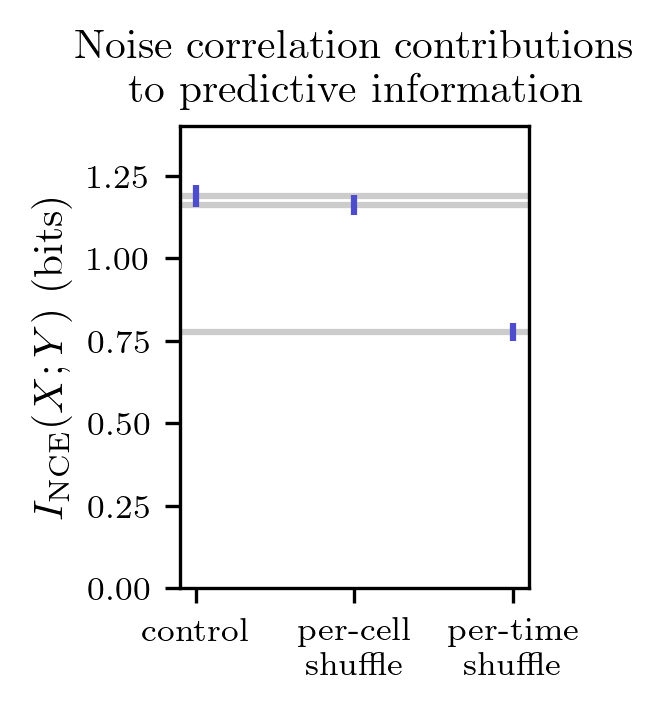

In [11]:
c1 = 0.3
c2 = 0.8
alp = 1
fig, ax = plt.subplots(dpi=300, figsize=[3*plot_scale, 4*plot_scale])

show_train = False

x = np.arange(len(trial_keys))
w = 0.1 if show_train else 0

for k, key in enumerate(trial_keys):
    if show_train:
        y = average_train[key] / np.log(2)
        yerr = stdevs_train[key] / np.log(2)
        ax.errorbar(x[k] - w, y, yerr, marker='', color=(c1,c2,c1))

    y = average_test[key] / np.log(2)
    yerr = stdevs_test[key] / np.log(2)
    ax.errorbar(x[k] + w, y, yerr, marker='', color=(c1,c1,c2), zorder=2)
    ax.axhline(y, color=(c2,c2,c2,alp), zorder=1)


ax.set_xticks(x)
ax.set_ylim(0,1.4)
ax.set_ylim(0)
# ax.set_xticklabels(trial_keys)
ax.set_xticklabels(["control", "per-cell\n shuffle", "per-time\n shuffle"])
ax.set_ylabel("$I_{\mathrm{NCE}}(X;Y)$ (bits)")
ax.set_title("Noise correlation contributions \n to predictive information") 
# ax.set_title(f"Trial shuffling with $N={N_neurons}$ neurons,\n $(V,B,E)={setup}$, under {stim} stim")
plt.savefig('./plots/trial shuffles.png', dpi=3000)

In [13]:
average_test['time'] / average_test['control']

0.6530435785073981

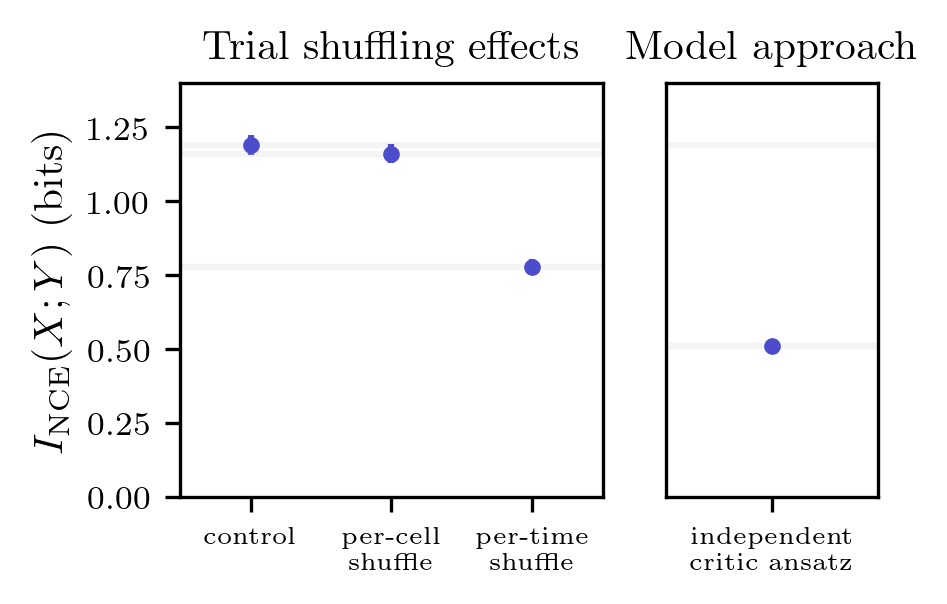

In [12]:
c1 = 0.3
c2 = 0.8
alp = 0.2
top = 0.8
# plot_scale = 0.88 / top * plot_scale


fig, ax = plt.subplots(ncols=2, dpi=300, figsize=[6*plot_scale,4*plot_scale], width_ratios=(4,2))

x = np.arange(len(trial_keys))
w = 0.5

for k, key in enumerate(trial_keys):
    y = average_test[key] / np.log(2)
    yerr = stdevs_test[key] / np.log(2)
    ax[0].errorbar(x[k], y, yerr, marker='.', color=(c1,c1,c2))
    ax[0].axhline(y, color=(c2,c2,c2,alp))
    if k == 0:
        ax[1].axhline(y, color=(c2,c2,c2,alp))

ax[0].set_xticks(x)
ax[0].set_xlim(-w,2+w)
# ax.set_ylim(0,1)
ax[0].set_ylim(0, 1.4)
# ax[0].set_xticklabels(trial_keys)
ax[0].set_xticklabels(["control", "per-cell\n shuffle", "per-time\n shuffle"], fontsize=6)
ax[0].set_ylabel("$I_{\mathrm{NCE}}(X;Y)$ (bits)")
ax[0].set_title("Trial shuffling effects")


y = average_test_auto / np.log(2)
yerr = stdevs_test_auto / np.log(2)
ax[1].errorbar(0, y, yerr, marker='.', color=(c1,c1,c2))
# ax[0].axhline(y, color=(c2,c2,c2,alp))
ax[1].axhline(y, color=(c2,c2,c2,alp))


ax[1].set_ylim(*ax[0].get_ylim())
# ax[1].set_xticks([])
ax[1].set_xticks([0])
ax[1].set_xticklabels(['independent\n critic ansatz'], fontsize=6)
ax[1].set_yticks([])
ax[1].set_title('Model approach', fontsize=10)


# fig.suptitle(r"Autocorrelations are important for prediction", fontsize=10)
fig.subplots_adjust(top=top)
# plt.savefig('./plots/autocorrelations.png', dpi=3000)